In [14]:
"""Video 7 - Python Heatmaps: correlation, calendar, and weekday x hour (custom brand colours).
Run:  pip install pandas numpy seaborn matplotlib   ->   python video07_heatmap_deep_dive.py
Needs sample_business_data.csv (Chart Pack) in the same folder for Heatmap 1.
Heatmaps 2 and 3 use SYNTHETIC data. Replace make_* functions with your own data.
Outputs: hm1_correlation.png, hm2_calendar.png, hm3_weekday_hour.png, hm4_palette_compare.png, hm_thumbnail_bg.png
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

NAVY, TEAL, PURPLE, GOLD = "#0F1419", "#1AC9A3", "#6B4FA6", "#D4AF37"
BRAND = LinearSegmentedColormap.from_list("brand", [NAVY, PURPLE, TEAL, GOLD])   # custom colormap
plt.rcParams.update({"text.color": "white", "axes.labelcolor": "white", "xtick.color": "white",
                     "ytick.color": "white", "font.size": 11})

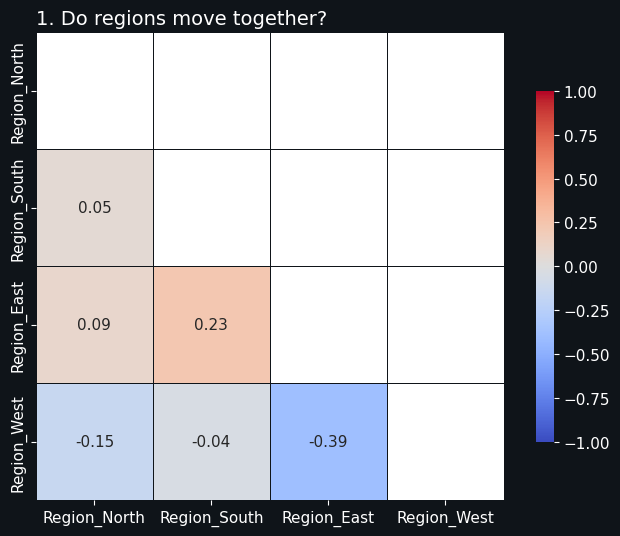

In [15]:
# ---- HEATMAP 1: correlation (masked triangle) -----------------------------
df = pd.read_csv("sample_business_data.csv", parse_dates=["Date"]).set_index("Date")
corr = df.pct_change().dropna().corr()                  # correlate % changes, not raw levels
mask = np.triu(np.ones_like(corr, dtype=bool))          # hide the redundant upper triangle
fig, ax = plt.subplots(figsize=(7, 5.5), facecolor=NAVY)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=.5, linecolor=NAVY, square=True, ax=ax, cbar_kws={"shrink": .75})
ax.set_title("1. Do regions move together?", color="white", loc="left", fontsize=14)
fig.tight_layout(); fig.savefig("hm1_correlation.png", dpi=150, facecolor=NAVY)

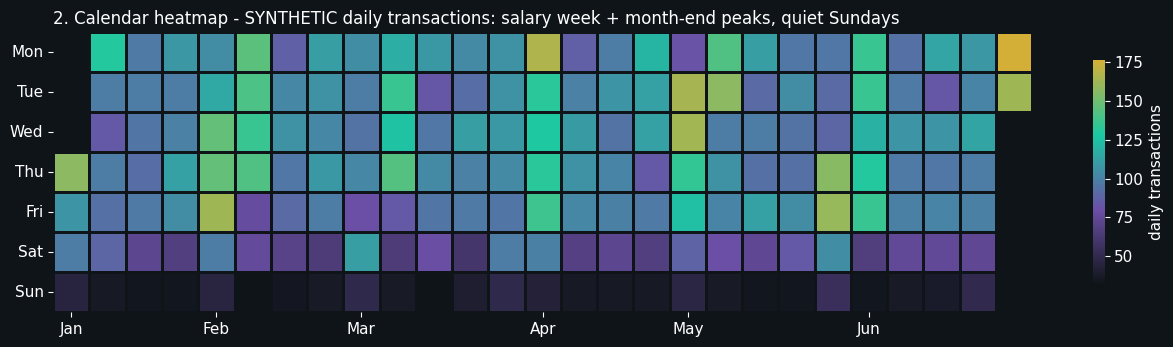

In [16]:
# ---- HEATMAP 2: calendar (GitHub-style) -----------------------------------
def make_daily(seed=3):
    rng = np.random.default_rng(seed)
    days = pd.date_range("2026-01-01", "2026-06-30")
    base = rng.normal(100, 8, len(days))
    base *= np.where(days.dayofweek == 6, .35, np.where(days.dayofweek == 5, .7, 1.0))   # Sundays low
    base *= np.where(days.day <= 5, 1.35, 1.0)                                        # salary week
    base *= np.where(days.is_month_end | (days.day >= 28), 1.5, 1.0)                  # month-end push
    return pd.Series(base.round(), index=days, name="txns")

daily = make_daily()
cal = pd.DataFrame({"v": daily.values, "wd": daily.index.dayofweek,
                    "wk": ((daily.index - daily.index[0]).days + daily.index[0].dayofweek) // 7})
grid = cal.pivot(index="wd", columns="wk", values="v")
fig, ax = plt.subplots(figsize=(13, 3.6), facecolor=NAVY); ax.set_facecolor(NAVY)   # empty cells = navy
sns.heatmap(grid, cmap=BRAND, linewidths=2, linecolor=NAVY, cbar_kws={"label": "daily transactions", "shrink": .8}, ax=ax)
ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
ticks = [(w, d.strftime("%b")) for w, d in zip(cal.wk, daily.index) if d.day == 1]
ax.set_xticks([w + .5 for w, _ in ticks]); ax.set_xticklabels([m for _, m in ticks], rotation=0)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("2. Calendar heatmap - SYNTHETIC daily transactions: salary week + month-end peaks, quiet Sundays",
             color="white", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig("hm2_calendar.png", dpi=150, facecolor=NAVY)

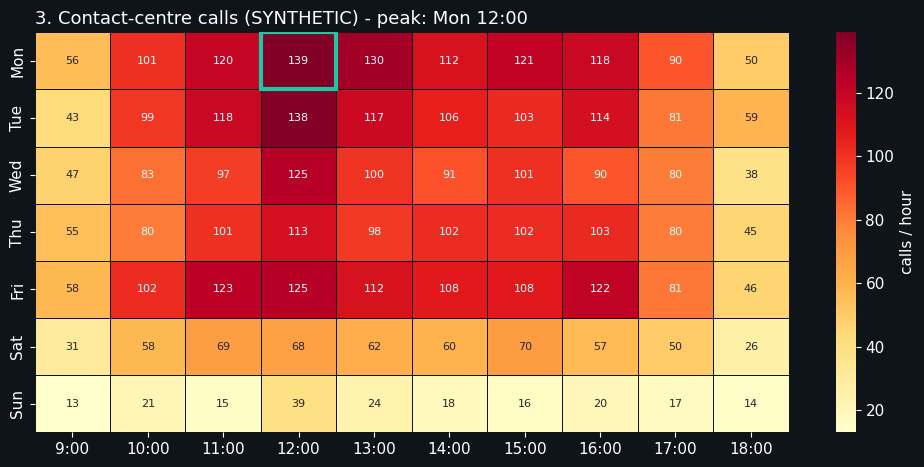

In [17]:
# ---- HEATMAP 3: weekday x hour (staffing view) ----------------------------
def make_calls(seed=9):
    rng = np.random.default_rng(seed)
    hours = np.arange(9, 19)
    peak = np.exp(-((hours - 11.5) ** 2) / 8) + .8 * np.exp(-((hours - 16) ** 2) / 6)
    wk = np.array([1.1, 1.0, .9, .95, 1.05, .6, .2])          # Mon..Sun
    m = np.outer(wk, peak) * 120 + rng.normal(0, 6, (7, len(hours)))
    return pd.DataFrame(m.clip(5).round(), index=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
                        columns=[f"{h}:00" for h in hours])

calls = make_calls()
fig, ax = plt.subplots(figsize=(10, 4.8), facecolor=NAVY)
sns.heatmap(calls, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 8}, linewidths=.5,
            linecolor=NAVY, cbar_kws={"label": "calls / hour"}, ax=ax)
r, c = np.unravel_index(calls.values.argmax(), calls.shape)
ax.add_patch(plt.Rectangle((c, r), 1, 1, fill=False, ec=TEAL, lw=3))
ax.set_title(f"3. Contact-centre calls (SYNTHETIC) - peak: {calls.index[r]} {calls.columns[c]}", color="white", loc="left", fontsize=13)
fig.tight_layout(); fig.savefig("hm3_weekday_hour.png", dpi=150, facecolor=NAVY)

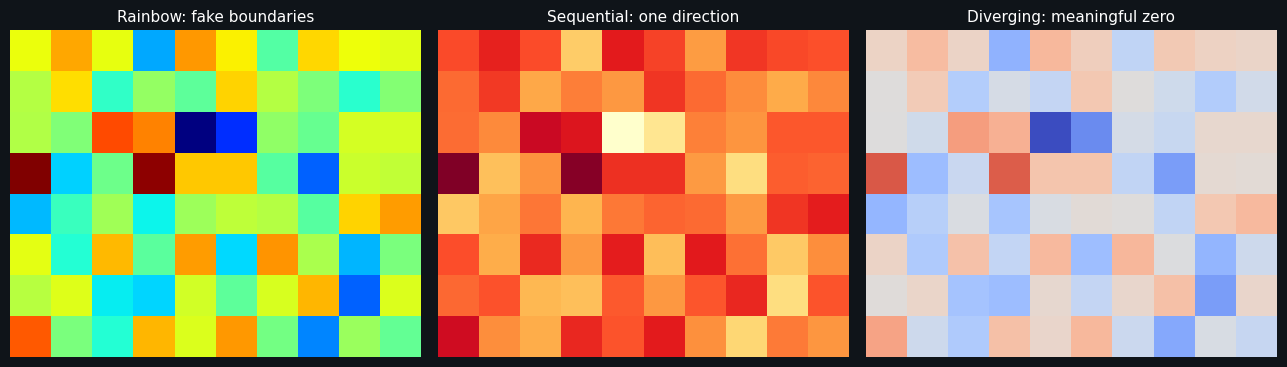

In [18]:
# ----  palette comparison (rainbow vs sequential vs diverging) ------
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), facecolor=NAVY)
z = np.random.default_rng(1).normal(0, 1, (8, 10))
for ax, (cmap, ttl, kw) in zip(axs, [("jet", "Rainbow: fake boundaries", {}),
                                     ("YlOrRd", "Sequential: one direction", {}),
                                     ("coolwarm", "Diverging: meaningful zero", {"center": 0})]):
    sns.heatmap(z, cmap=cmap, cbar=False, xticklabels=False, yticklabels=False, ax=ax, **kw)
    ax.set_title(ttl, color="white", fontsize=11)
fig.tight_layout(); fig.savefig("hm4_palette_compare.png", dpi=150, facecolor=NAVY)